# Actividad 4 · Modelado y Estrategia Comercial
**North Quay Gifts · Online Retail II** — Equipo: Chan, Castillo, Soriano, Pacheco

Trabajamos con la **ruta B** (compras netas de abonos), igual que en las actividades 2 y 3. Todas las cifras de dinero están en GBP.

| Sección | Archivo | Periodo |
|---|---|---|
| I. Pronóstico | `indicadores_diarios.csv` | 01-dic-2009 a 09-dic-2011 |
| II. Clasificación | `clientes_clasificacion.csv` | 180 días antes del 01-jul-2011 y 90 días después |
| III. Clustering | `clientes_rfm.csv` | historial completo, referencia 10-dic-2011 |

Cada sección usa una población y un periodo distintos, así que no las mezclamos.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42           # misma semilla en partición, árbol y K-Means
DATA = "../data/"   # carpeta con los CSV (ruta B); en Google Colab usa "/content/"

os.makedirs("figs", exist_ok=True)
sns.set_theme(style="whitegrid")

azul, naranja, gris = "#2a78d6", "#eb6834", "#898781"

def gbp(x):
    return f"£{x:,.0f}"

# aquí vamos guardando las cifras que usamos en slides y reporte
RES = {"ruta": "B", "semilla": SEED}

In [2]:
# comprobamos que indicadores_diarios.csv corresponde a la ruta B
diario = pd.read_csv(DATA + "indicadores_diarios.csv", parse_dates=["Date"])
diario = diario.sort_values("Date").reset_index(drop=True)
comp = pd.read_csv(DATA + "indicadores_diarios_comparacion.csv", parse_dates=["Date"])

for ruta in ["A", "B"]:
    x = comp[comp["Route"] == ruta].merge(diario, on="Date", suffixes=("_comp", ""))
    dif = (x["Revenue_comp"] - x["Revenue"]).abs().max()
    print("Ruta", ruta, "- diferencia máxima con indicadores_diarios:", gbp(dif))

total = comp.groupby("Route")["Revenue"].sum()
print("Total ruta A:", gbp(total["A"]), "| Total ruta B:", gbp(total["B"]))

Ruta A - diferencia máxima con indicadores_diarios: £168,789
Ruta B - diferencia máxima con indicadores_diarios: £0
Total ruta A: £20,476,260 | Total ruta B: £19,013,836


---
# I. Regresión y pronóstico de ventas

## I.1 Cobertura de fechas
Primero revisamos qué fechas faltan antes de crear rezagos. No las rellenamos con ceros porque son días sin operación, no días con venta cero.

In [3]:
todas = pd.date_range(diario["Date"].min(), diario["Date"].max(), freq="D")
faltan = todas.difference(diario["Date"])
print("Días observados:", len(diario), "de", len(todas), "| ausentes:", len(faltan))

dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
cobertura = pd.DataFrame({
    "observados": diario["Date"].dt.dayofweek.value_counts().sort_index(),
    "ausentes": pd.Series(faltan.dayofweek).value_counts().sort_index(),
    "mediana_revenue": diario.groupby(diario["Date"].dt.dayofweek)["Revenue"].median().round(0),
}).fillna(0)
cobertura.index = dias
cobertura

Días observados: 604 de 739 | ausentes: 135


,observados,ausentes,mediana_revenue
Lun,94,11,28772.0
Mar,104,2,31439.0
Mié,104,2,28341.0
Jue,103,3,34093.0
Vie,99,7,27093.0
Sáb,1,104,9803.0
Dom,99,6,17051.0


In [4]:
# ausencias que no son sábado
print([d.date() for d in faltan if d.dayofweek != 5])

# días con revenue negativo (abonos mayores que compras)
diario[diario["Revenue"] <= 0]

[datetime.date(2009, 12, 24), datetime.date(2009, 12, 25), datetime.date(2009, 12, 27), datetime.date(2009, 12, 28), datetime.date(2009, 12, 29), datetime.date(2009, 12, 30), datetime.date(2009, 12, 31), datetime.date(2010, 1, 1), datetime.date(2010, 1, 3), datetime.date(2010, 4, 2), datetime.date(2010, 4, 4), datetime.date(2010, 4, 5), datetime.date(2010, 5, 3), datetime.date(2010, 5, 31), datetime.date(2010, 8, 30), datetime.date(2010, 12, 24), datetime.date(2010, 12, 26), datetime.date(2010, 12, 27), datetime.date(2010, 12, 28), datetime.date(2010, 12, 29), datetime.date(2010, 12, 30), datetime.date(2010, 12, 31), datetime.date(2011, 1, 2), datetime.date(2011, 1, 3), datetime.date(2011, 4, 22), datetime.date(2011, 4, 24), datetime.date(2011, 4, 25), datetime.date(2011, 4, 29), datetime.date(2011, 5, 2), datetime.date(2011, 5, 30), datetime.date(2011, 8, 29)]


,Date,TotalOrders,TotalUnits,Revenue
218,2010-08-27,36,7307,-1727.65
320,2011-01-05,55,19497,-1570.43


### Lo que encontramos en las fechas

El archivo tiene 604 días con ventas de 739 días calendario. Casi todos los faltantes son sábados: la tienda no registra ventas ese día (solo aparece un sábado, el 5 de diciembre de 2009, al inicio del historial). Las otras 31 ausencias coinciden con el cierre de Navidad y Año Nuevo y con los días festivos del Reino Unido. Por eso trabajamos con los días hábiles que sí aparecen y no inventamos días con venta cero.

Hay dos días con Revenue negativo. Los dejamos porque son reales en la ruta B: ese día los abonos fueron mayores que las compras.

En la gráfica se ve que las ventas suben mucho de septiembre a noviembre (noviembre de 2010 cerró con £1.42M y noviembre de 2011 con £1.46M) y bajan después de mediados de diciembre. Diciembre de 2011 aparece incompleto porque solo tiene 8 días.

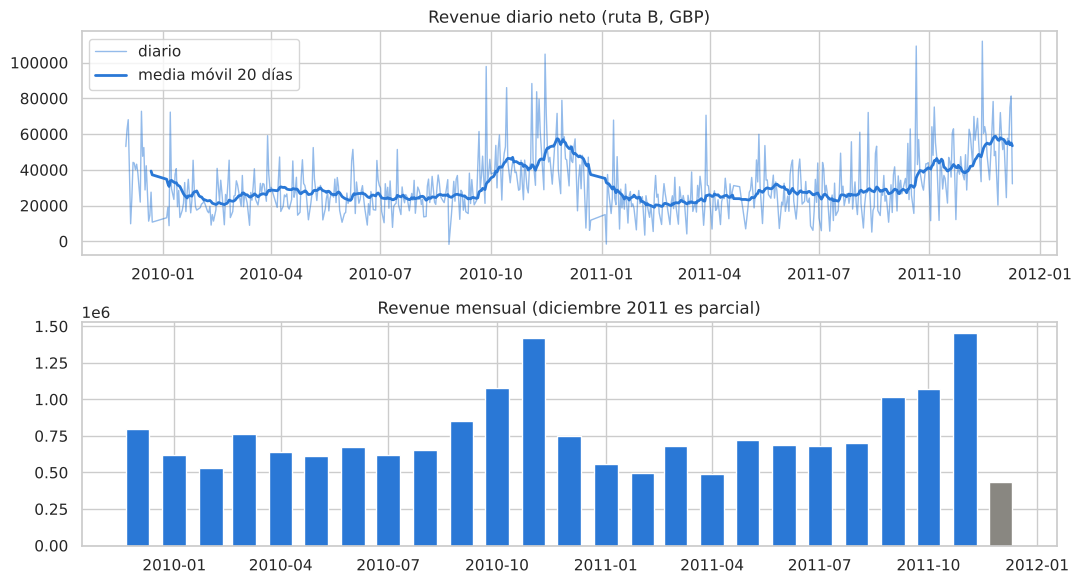

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6))

ax[0].plot(diario["Date"], diario["Revenue"], color=azul, lw=1, alpha=0.5, label="diario")
ax[0].plot(diario["Date"], diario["Revenue"].rolling(20).mean(), color=azul, lw=2, label="media móvil 20 días")
ax[0].set_title("Revenue diario neto (ruta B, GBP)")
ax[0].legend()

mensual = diario.set_index("Date")["Revenue"].resample("MS").sum()
colores = [gris if fecha == mensual.index[-1] else azul for fecha in mensual.index]
ax[1].bar(mensual.index, mensual, width=20, color=colores)
ax[1].set_title("Revenue mensual (diciembre 2011 es parcial)")

plt.tight_layout()
plt.savefig("figs/I_serie_revenue.png", dpi=150)
plt.show()

## I.2 Diseño del pronóstico

- **Objetivo:** Revenue diario neto (GBP).
- **Unidad:** día hábil observado (cada fila del archivo).
- **Tipo:** un paso adelante. Al cierre de cada día pronosticamos el siguiente día hábil.
- **Prueba:** del 17-oct al 09-dic-2011 (8 semanas de temporada alta). La usamos una sola vez al final.
- **Validación:** `TimeSeriesSplit` con 5 cortes de 40 días dentro del entrenamiento.

**Qué sabemos al pronosticar:** solo ventas de días ya cerrados (por eso todo usa `shift(1)`) y el calendario del día que se pronostica. No usamos pedidos ni unidades del mismo día.

**Rezagos:** `lag1` es el último día hábil, que puede estar a 1 o más días calendario (por eso agregamos `gap_dias`). Para comparar con la semana anterior no usamos "7 filas atrás", sino el último día observado con el mismo día de la semana.

In [6]:
def crear_variables(df, col="Revenue"):
    y = df[col]
    f = pd.DataFrame({"Date": df["Date"]})

    # información de días anteriores
    f["lag1"] = y.shift(1)
    f["lag2"] = y.shift(2)
    f["mismo_dia_sem_previo"] = y.groupby(df["Date"].dt.dayofweek).shift(1)
    f["ma5"] = y.shift(1).rolling(5).mean()
    f["ma20"] = y.shift(1).rolling(20).mean()

    # calendario del día que se pronostica
    f["gap_dias"] = df["Date"].diff().dt.days
    semana = df["Date"].dt.isocalendar().week.astype(float)
    f["sem_sin"] = np.sin(2 * np.pi * semana / 52)
    f["sem_cos"] = np.cos(2 * np.pi * semana / 52)
    dia = pd.get_dummies(df["Date"].dt.dayofweek, prefix="dow", dtype=float)
    dia = dia.drop(columns="dow_5")   # solo hay un sábado en todo el historial
    mes = pd.get_dummies(df["Date"].dt.month, prefix="mes", dtype=float)

    f = pd.concat([f, dia, mes], axis=1)
    f["y"] = y
    return f.dropna().reset_index(drop=True)


INICIO_PRUEBA = "2011-10-17"
datos = crear_variables(diario)
train = datos[datos["Date"] < INICIO_PRUEBA]
test = datos[datos["Date"] >= INICIO_PRUEBA]

cols_dia = [c for c in datos.columns if c.startswith("dow_")]
cols_mes = [c for c in datos.columns if c.startswith("mes_")]
vars_base = ["lag1", "mismo_dia_sem_previo", "ma5", "ma20"] + cols_dia
vars_cal = vars_base + ["lag2", "gap_dias", "sem_sin", "sem_cos"]
vars_cal_mes = vars_cal + cols_mes

print("Train:", train["Date"].min().date(), "a", train["Date"].max().date(), "-", len(train), "días")
print("Test: ", test["Date"].min().date(), "a", test["Date"].max().date(), "-", len(test), "días")

Train: 2009-12-23 a 2011-10-16 - 537 días
Test:  2011-10-17 a 2011-12-09 - 47 días


## I.3 Selección del modelo con validación
Comparamos en los mismos 5 cortes:
- **Referencias:** último valor, mismo día de la semana anterior y media de 5 días.
- **Modelo inicial:** Ridge con rezagos y día de la semana.
- **Alternativas:** Ridge + calendario, Ridge + calendario + mes y Gradient Boosting.

El `StandardScaler` va dentro del pipeline, así que solo se ajusta con el entrenamiento de cada corte. Elegimos el menor MAE promedio.

In [7]:
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
gb = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300,
                                   min_samples_leaf=20, random_state=SEED)

modelos = {
    "Ridge rezagos (inicial)": (ridge, vars_base),
    "Ridge + calendario": (ridge, vars_cal),
    "Ridge + calendario + mes": (ridge, vars_cal_mes),
    "Gradient Boosting + calendario": (gb, vars_cal),
}
referencias = {
    "Último valor": "lag1",
    "Mismo día semana previa": "mismo_dia_sem_previo",
    "Media 5 días previos": "ma5",
}

tscv = TimeSeriesSplit(n_splits=5, test_size=40)
resultados = []

for nombre, (modelo, cols) in modelos.items():
    errores = []
    for idx_tr, idx_val in tscv.split(train):
        m = clone(modelo).fit(train.iloc[idx_tr][cols], train.iloc[idx_tr]["y"])
        p = m.predict(train.iloc[idx_val][cols])
        errores.append(mean_absolute_error(train.iloc[idx_val]["y"], p))
    resultados.append([nombre, "modelo"] + errores)

for nombre, col in referencias.items():
    errores = []
    for idx_tr, idx_val in tscv.split(train):
        errores.append(mean_absolute_error(train.iloc[idx_val]["y"], train.iloc[idx_val][col]))
    resultados.append([nombre, "referencia"] + errores)

cv = pd.DataFrame(resultados, columns=["modelo", "tipo", "corte1", "corte2", "corte3", "corte4", "corte5"])
cortes = ["corte1", "corte2", "corte3", "corte4", "corte5"]
cv["MAE_medio"] = cv[cortes].mean(axis=1)
cv["desv"] = cv[cortes].std(axis=1, ddof=0)
cv = cv.sort_values("MAE_medio").reset_index(drop=True)

ELEGIDO = cv[cv["tipo"] == "modelo"]["modelo"].iloc[0]
INICIAL = "Ridge rezagos (inicial)"
print("Modelo elegido:", ELEGIDO)
cv.round(0)

Modelo elegido: Ridge + calendario + mes


,modelo,tipo,corte1,corte2,corte3,corte4,corte5,MAE_medio,desv
0,Ridge + calendario + mes,modelo,6170.0,5816.0,8058.0,9971.0,10843.0,8172.0,1997.0
1,Ridge + calendario,modelo,5652.0,5789.0,8205.0,10693.0,11068.0,8281.0,2311.0
2,Ridge rezagos (inicial),modelo,6013.0,5772.0,8116.0,10451.0,11137.0,8298.0,2206.0
3,Gradient Boosting + calendario,modelo,7132.0,7070.0,7777.0,9991.0,12591.0,8912.0,2123.0
4,Media 5 días previos,referencia,8514.0,8227.0,10690.0,11875.0,14221.0,10705.0,2221.0
5,Mismo día semana previa,referencia,6681.0,9128.0,11138.0,9766.0,17453.0,10833.0,3611.0
6,Último valor,referencia,11728.0,10359.0,11892.0,15658.0,18662.0,13660.0,3058.0


### Qué modelo elegimos

Los tres modelos Ridge le ganaron a todas las referencias en 4 de los 5 cortes; en el corte 4 (julio-agosto de 2011) la referencia del mismo día de la semana anterior fue un poco mejor (£9,766 contra £9,971 de nuestro modelo). En el promedio de los 5 cortes, el que tuvo menor error promedio fue **Ridge + calendario + mes**, con un MAE de £8,172 contra £10,833 de la referencia del mismo día de la semana anterior (25% menos). También fue el más estable entre cortes, así que nos quedamos con ese.

El Gradient Boosting salió peor que la regresión lineal. Creemos que con unos 500 días de entrenamiento no le alcanza para aprovechar su flexibilidad, y la relación entre la venta y sus días anteriores es bastante lineal.

Algo que hay que tomar en cuenta: los cortes de validación van de febrero a octubre de 2011, así que ninguno incluyó noviembre ni diciembre. Lo que el modelo sabe de esos meses lo aprendió solo de 2010.

## I.4 Evaluación en prueba
Reentrenamos con todo el entrenamiento y evaluamos en las mismas 47 fechas que las referencias.

In [8]:
def metricas(real, pred):
    return {"MAE": mean_absolute_error(real, pred),
            "RMSE": mean_squared_error(real, pred) ** 0.5,
            "R2": r2_score(real, pred)}

pred = pd.DataFrame({"Date": test["Date"].values, "Real": test["y"].values})
for nombre in [ELEGIDO, INICIAL]:
    modelo, cols = modelos[nombre]
    m = clone(modelo).fit(train[cols], train["y"])
    pred[nombre] = m.predict(test[cols])
for nombre, col in referencias.items():
    pred[nombre] = test[col].values

REF = "Mismo día semana previa"
tabla = pd.DataFrame({n: metricas(pred["Real"], pred[n]) for n in pred.columns[2:]}).T
tabla["mejora_vs_ref_%"] = (1 - tabla["MAE"] / tabla.loc[REF, "MAE"]) * 100
tabla["MAE_sobre_media_%"] = tabla["MAE"] / pred["Real"].mean() * 100

print("Revenue medio diario en prueba:", gbp(pred["Real"].mean()))

RES["pronostico"] = {
    "test": [str(test["Date"].min().date()), str(test["Date"].max().date()), len(test)],
    "elegido": ELEGIDO,
    "referencia": REF,
    "metricas": tabla.round(3).to_dict("index"),
    "revenue_medio_test": round(pred["Real"].mean(), 2),
}
tabla.round(3)

Revenue medio diario en prueba: £51,868


,MAE,RMSE,R2,mejora_vs_ref_%,MAE_sobre_media_%
Ridge + calendario + mes,10480.904,15001.742,0.255,20.817,20.207
Ridge rezagos (inicial),11571.563,15483.182,0.207,12.577,22.310
Último valor,17863.575,23718.271,-0.862,-34.959,34.440
Mismo día semana previa,13236.251,17703.615,-0.037,0.000,25.519
Media 5 días previos,14086.545,18860.800,-0.177,-6.424,27.158


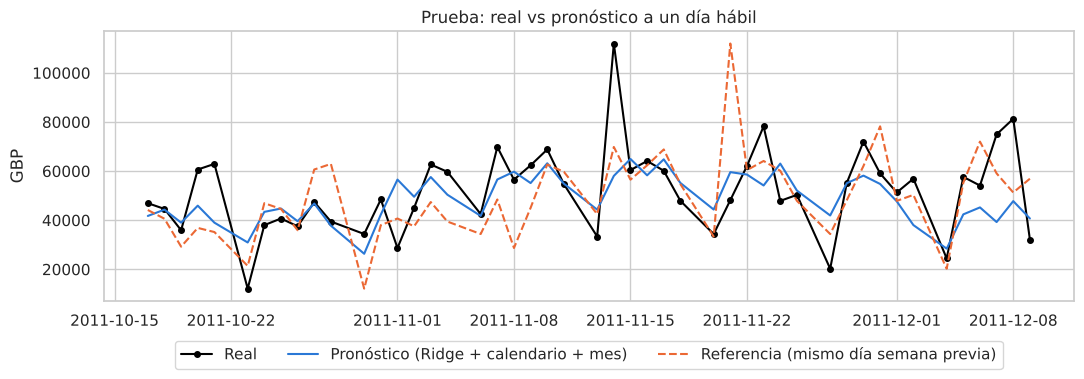

In [9]:
plt.figure(figsize=(11, 4))
plt.plot(pred["Date"], pred["Real"], color="black", marker="o", ms=4, label="Real")
plt.plot(pred["Date"], pred[ELEGIDO], color=azul, label="Pronóstico (" + ELEGIDO + ")")
plt.plot(pred["Date"], pred[REF], color=naranja, ls="--", lw=1.5, label="Referencia (mismo día semana previa)")
plt.title("Prueba: real vs pronóstico a un día hábil")
plt.ylabel("GBP")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.tight_layout()
plt.savefig("figs/I_real_vs_pronostico.png", dpi=150)
plt.show()

## I.5 Los dos mayores errores y el sesgo

In [10]:
pred["Error"] = pred["Real"] - pred[ELEGIDO]   # positivo = subestimamos
top2 = pred.loc[pred["Error"].abs().nlargest(2).index, ["Date", "Real", ELEGIDO, REF, "Error"]]
top2["error_vs_media_%"] = top2["Error"] / pred["Real"].mean() * 100

sub = (pred["Error"] > 0).sum()
sobre = (pred["Error"] < 0).sum()
print("Días subestimados:", sub, "| sobreestimados:", sobre, "| sesgo medio:", gbp(pred["Error"].mean()))
top2.round(0)

Días subestimados: 27 | sobreestimados: 20 | sesgo medio: £3,282


/tmp/ipykernel_230/2211129062.py:8: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  top2.round(0)


,Date,Real,Ridge + calendario + mes,Mismo día semana previa,Error,error_vs_media_%
24,2011-11-14,111959.0,58038.0,69825.0,53920.0,104.0
44,2011-12-07,74953.0,39244.0,59050.0,35708.0,69.0


In [11]:
# sumamos los pronósticos diarios por semana (la última semana termina el viernes 9-dic)
semanal = pred.set_index("Date")[["Real", ELEGIDO, REF]].resample("W-SUN").sum()
semanal["error_modelo_%"] = (semanal["Real"] - semanal[ELEGIDO]) / semanal["Real"] * 100
semanal["error_ref_%"] = (semanal["Real"] - semanal[REF]) / semanal["Real"] * 100

RES["pronostico"]["top2"] = [{"fecha": str(r["Date"].date()), "real": round(r["Real"]),
                              "pron": round(r[ELEGIDO]), "error": round(r["Error"])} for _, r in top2.iterrows()]
RES["pronostico"]["dias_sub"] = int(sub)
RES["pronostico"]["dias_sobre"] = int(sobre)
RES["pronostico"]["sesgo_medio"] = round(pred["Error"].mean())
RES["pronostico"]["error_semanal_modelo_%"] = round(semanal["error_modelo_%"].abs().mean(), 2)
RES["pronostico"]["error_semanal_ref_%"] = round(semanal["error_ref_%"].abs().mean(), 2)

print("Error semanal absoluto medio - modelo:", round(semanal["error_modelo_%"].abs().mean(), 1), "%",
      "| referencia:", round(semanal["error_ref_%"].abs().mean(), 1), "%")
semanal.round(1)

Error semanal absoluto medio - modelo: 9.0 % | referencia: 13.0 %


,Real,Ridge + calendario + mes,Mismo día semana previa,error_modelo_%,error_ref_%
Date,,,,,
2011-10-23,263103.8,240865.5,207345.6,8.5,21.2
2011-10-30,237399.1,238583.6,263103.8,-0.5,-10.8
2011-11-06,287017.9,298069.6,237399.1,-3.9,17.3
2011-11-13,345524.7,333803.7,287017.9,3.4,16.9
2011-11-20,378849.8,345534.1,345524.7,8.8,8.8
2011-11-27,306886.9,329344.6,378849.8,-7.3,-23.4
2011-12-04,318902.9,282079.5,306886.9,11.5,3.8
2011-12-11,300116.4,215279.5,294481.0,28.3,1.9


Misma información en una gráfica por semana (en miles de libras). Esta es la gráfica que usamos en la presentación, porque para planear se lee mejor por semana que por día.

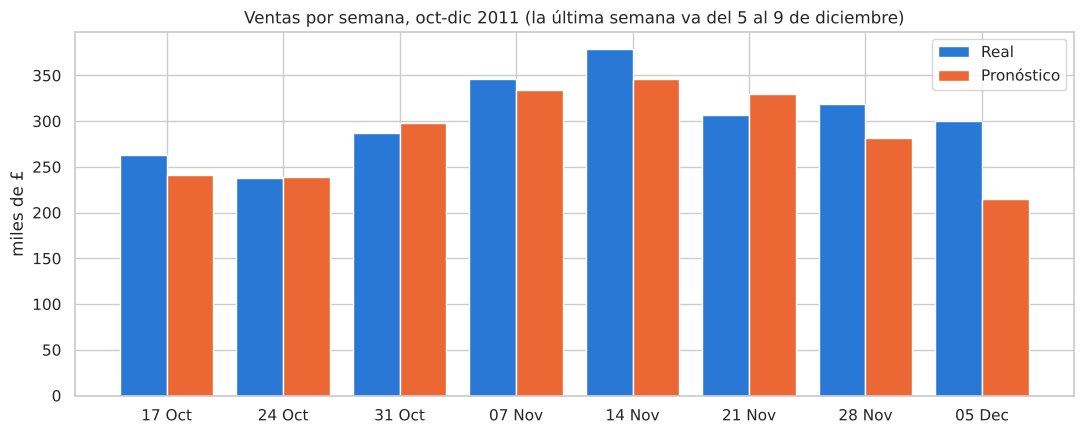

,Real,Ridge + calendario + mes
Date,,
2011-10-23,263.0,241.0
2011-10-30,237.0,239.0
2011-11-06,287.0,298.0
2011-11-13,346.0,334.0
2011-11-20,379.0,346.0
2011-11-27,307.0,329.0
2011-12-04,319.0,282.0
2011-12-11,300.0,215.0


In [12]:
# gráfica semanal: real contra pronóstico, en miles de libras
etiquetas = [d.strftime("%d %b") for d in semanal.index - pd.Timedelta(days=6)]   # lunes de cada semana
x = np.arange(len(semanal))

plt.figure(figsize=(11, 4.5))
plt.bar(x - 0.2, semanal["Real"] / 1000, width=0.4, color=azul, label="Real")
plt.bar(x + 0.2, semanal[ELEGIDO] / 1000, width=0.4, color=naranja, label="Pronóstico")
plt.xticks(x, etiquetas)
plt.ylabel("miles de £")
plt.title("Ventas por semana, oct-dic 2011 (la última semana va del 5 al 9 de diciembre)")
plt.legend()
plt.tight_layout()
plt.savefig("figs/I_ventas_semanales.png", dpi=150)
plt.show()

(semanal[["Real", ELEGIDO]] / 1000).round(0)

### Cómo le fue al modelo en la prueba

En las 47 fechas de prueba, nuestro modelo tuvo un MAE de £10,481 y la referencia de £13,236, o sea, **21% menos error por día**. Contra el último valor la mejora es de 41%. El modelo inicial (solo con rezagos) mejoró 13%, así que agregar el calendario sí ayudó. Aun así, el R² de 0.26 nos dice que buena parte de la variación diaria no la explicamos: el error típico es de alrededor del 20% de la venta promedio diaria (£51,868).

Los dos errores más grandes fueron días en que nos quedamos cortos:

1. **Lunes 14 de noviembre de 2011.** Se vendieron £111,959 y pronosticamos £58,038, casi £54,000 menos. Fue el día con más ventas de todo el historial y nada en los días anteriores lo anticipaba.
2. **Miércoles 7 de diciembre de 2011.** Se vendieron £74,953 y pronosticamos £39,244. Aquí el problema es que el modelo aprendió que diciembre vende mucho menos que noviembre, porque el único diciembre que vio (2010) incluye el cierre navideño. En 2011 la primera semana de diciembre siguió fuerte, por eso la última semana de prueba quedó 28% abajo.

Para darle tamaño: con un ingreso promedio de £525 por pedido, quedarnos cortos por £54,000 en un día es como no tener listos unos 100 pedidos. Si se usara el pronóstico para decidir personal de almacén e inventario, ese día no alcanzaría la capacidad.

**¿Qué sale más caro, pasarnos o quedarnos cortos?** En esta temporada, quedarnos cortos. El modelo subestimó 27 de los 47 días y los errores grandes fueron hacia abajo. Quedarse corto en noviembre significa faltantes y retrasos justo cuando más se vende. Pasarse deja inventario de temporada que después de diciembre vale menos. Como no tenemos los costos de cada caso, no podemos decir cuánto pesa cada uno, pero proponemos planear con el pronóstico más un margen extra en noviembre.

Si sumamos los pronósticos por semana, el error promedio baja a 9.0% (contra 13.0% de la referencia). Por eso lo vemos más útil para planear la semana que para fijar la cifra exacta de un día.

## I.6 Complemento: pedidos (TotalOrders)
Usamos la misma preparación y el modelo elegido para pronosticar pedidos. Aquí los pedidos son el objetivo, nunca una variable del Revenue.

In [13]:
datos_ped = crear_variables(diario, col="TotalOrders")
train_ped = datos_ped[datos_ped["Date"] < INICIO_PRUEBA]
test_ped = datos_ped[datos_ped["Date"] >= INICIO_PRUEBA]

modelo, cols = modelos[ELEGIDO]
m = clone(modelo).fit(train_ped[cols], train_ped["y"])
p_ped = m.predict(test_ped[cols])

tabla_ped = pd.DataFrame({
    ELEGIDO: metricas(test_ped["y"], p_ped),
    REF: metricas(test_ped["y"], test_ped["mismo_dia_sem_previo"]),
}).T
RES["pronostico"]["pedidos"] = tabla_ped.round(3).to_dict("index")

print("Pedidos promedio por día:", round(test_ped["y"].mean(), 1))
print("Ingreso promedio por pedido:", gbp(test["y"].sum() / test_ped["y"].sum()))
tabla_ped.round(3)

Pedidos promedio por día: 98.8
Ingreso promedio por pedido: £525


,MAE,RMSE,R2
Ridge + calendario + mes,13.537,17.194,0.443
Mismo día semana previa,15.234,21.186,0.155


### Pedidos

Con el mismo modelo, el pronóstico de pedidos tiene un error de 13.5 pedidos por día (R² de 0.44), contra 15.2 de la referencia. Los pedidos son más fáciles de pronosticar que el ingreso porque el ingreso también depende de qué tan grande es cada pedido, y eso cambia mucho entre clientes mayoristas. Para la operación (preparar y enviar) usaríamos el pronóstico de pedidos, y para metas de venta el de Revenue.

Para mejorar el pronóstico nos ayudaría tener el calendario de promociones y envíos de catálogo, los pedidos grandes que se confirman con anticipación, más años de historia de noviembre y diciembre, y el costo real de quedarse sin inventario contra el de que sobre.

---
# II. Clasificación y estrategias de recompra
Clientes con compra en los 180 días antes del **1 de julio de 2011**. Variables: `RecencyDays`, `TotalOrders` y `TotalSpent` (GBP netos). Etiqueta: `Repurchase90Days`. **Clase positiva = 1.** No usamos `CustomerID`.

In [14]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

clientes = pd.read_csv(DATA + "clientes_clasificacion.csv")
X = clientes[["RecencyDays", "TotalOrders", "TotalSpent"]]
y = clientes["Repurchase90Days"]

print(y.value_counts())
print(y.value_counts(normalize=True).round(3))
print("Clientes con TotalSpent <= 0:", (clientes["TotalSpent"] <= 0).sum())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", len(X_train), "| Test:", len(X_test))
X.describe().round(1)

Repurchase90Days
1    1409
0    1315
Name: count, dtype: int64
Repurchase90Days
1    0.517
0    0.483
Name: proportion, dtype: float64
Clientes con TotalSpent <= 0: 8
Train: 2179 | Test: 545


,RecencyDays,TotalOrders,TotalSpent
count,2724.0,2724.0,2724.0
mean,60.8,2.7,1164.0
std,47.9,3.9,4125.9
min,1.0,1.0,-1591.2
25%,21.0,1.0,236.9
50%,47.0,2.0,482.0
75%,95.0,3.0,1039.3
max,178.0,67.0,127365.2


## II.1 Árbol inicial y búsqueda de parámetros
- **Árbol inicial:** sin restricciones.
- **Búsqueda:** `max_depth` en {3, 4, 5} y `min_samples_leaf` en {20, 50, 100}, con validación cruzada estratificada de 5 partes **solo en entrenamiento**.
- **Métrica principal: F1 de la clase 1.** Usamos el árbol para dos públicos: fidelización (predichos 1) y reactivación (predichos 0). Un falso positivo deja a un cliente que no regresó sin reactivación, y un falso negativo gasta un contacto en alguien que habría regresado solo. F1 toma en cuenta los dos errores.

In [15]:
arbol_inicial = DecisionTreeClassifier(random_state=SEED)
arbol_inicial.fit(X_train, y_train)

parametros = {"max_depth": [3, 4, 5], "min_samples_leaf": [20, 50, 100]}
cv_estrat = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
busqueda = GridSearchCV(DecisionTreeClassifier(random_state=SEED), parametros, scoring="f1", cv=cv_estrat)
busqueda.fit(X_train, y_train)
arbol = busqueda.best_estimator_   # ya viene reentrenado con todo el train

print("Mejores parámetros:", busqueda.best_params_, "| F1 en validación:", round(busqueda.best_score_, 3))
print("Árbol inicial:", arbol_inicial.get_depth(), "niveles,", arbol_inicial.get_n_leaves(), "hojas")
print("Árbol elegido:", arbol.get_depth(), "niveles,", arbol.get_n_leaves(), "hojas")

grid = pd.DataFrame(busqueda.cv_results_)
grid[["param_max_depth", "param_min_samples_leaf", "mean_test_score", "std_test_score"]].round(3)

Mejores parámetros: {'max_depth': 4, 'min_samples_leaf': 50} | F1 en validación: 0.681
Árbol inicial: 30 niveles, 726 hojas
Árbol elegido: 4 niveles, 15 hojas


,param_max_depth,param_min_samples_leaf,mean_test_score,std_test_score
0,3,20,0.681,0.029
1,3,50,0.677,0.025
2,3,100,0.679,0.030
3,4,20,0.679,0.009
4,4,50,0.681,0.009
5,4,100,0.680,0.017
6,5,20,0.665,0.021
7,5,50,0.663,0.018
8,5,100,0.667,0.028


## II.2 Comparación Train vs Test

In [16]:
def evaluar(modelo, X, y):
    p = modelo.predict(X)
    return {"Accuracy": accuracy_score(y, p),
            "Precision_1": precision_score(y, p),
            "Recall_1": recall_score(y, p),
            "F1_1": f1_score(y, p),
            "Precision_0": precision_score(y, p, pos_label=0),
            "Recall_0": recall_score(y, p, pos_label=0)}

comparacion = pd.DataFrame({
    "Inicial - Train": evaluar(arbol_inicial, X_train, y_train),
    "Inicial - Test": evaluar(arbol_inicial, X_test, y_test),
    "Elegido - Train": evaluar(arbol, X_train, y_train),
    "Elegido - Test": evaluar(arbol, X_test, y_test),
}).T
comparacion.round(3)

,Accuracy,Precision_1,Recall_1,F1_1,Precision_0,Recall_0
Inicial - Train,1.000,1.000,1.000,1.000,1.000,1.000
Inicial - Test,0.618,0.624,0.660,0.641,0.611,0.574
Elegido - Train,0.702,0.724,0.686,0.704,0.681,0.720
Elegido - Test,0.716,0.759,0.660,0.706,0.680,0.776


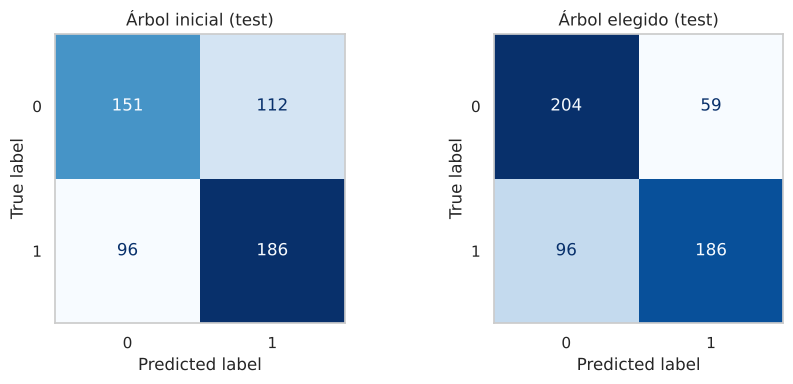

VP: 186 | FP: 59 | FN: 96 | VN: 204


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ConfusionMatrixDisplay.from_estimator(arbol_inicial, X_test, y_test, ax=ax[0], cmap="Blues", colorbar=False)
ConfusionMatrixDisplay.from_estimator(arbol, X_test, y_test, ax=ax[1], cmap="Blues", colorbar=False)
ax[0].set_title("Árbol inicial (test)")
ax[1].set_title("Árbol elegido (test)")
for a in ax:
    a.grid(False)
plt.tight_layout()
plt.savefig("figs/II_matrices_confusion.png", dpi=150)
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, arbol.predict(X_test)).ravel()
print("VP:", tp, "| FP:", fp, "| FN:", fn, "| VN:", tn)

RES["clasificacion"] = {
    "params": busqueda.best_params_,
    "f1_cv": round(busqueda.best_score_, 4),
    "metricas": comparacion.round(4).to_dict("index"),
    "cm_test": {"VP": int(tp), "FP": int(fp), "FN": int(fn), "VN": int(tn)},
}

### Train contra Test

El árbol inicial, sin límites, creció hasta 30 niveles y 726 hojas. Acierta el 100% en entrenamiento pero solo el 61.8% en prueba: se aprendió a cada cliente de memoria, que es sobreajuste.

El árbol que elegimos (profundidad 4 y mínimo 50 clientes por hoja) tiene 15 hojas y resultados casi iguales en entrenamiento y prueba (F1 de 0.704 y 0.706). Eso nos dice que generaliza bien. Que en prueba salga un poco mejor lo vemos como variación normal de una muestra de 545 clientes.

Comparado con el árbol inicial en prueba, el elegido sube la precisión de la clase 1 de 0.624 a 0.759 con el mismo recall (0.660), y sube el recall de la clase 0 de 0.574 a 0.776. Es decir, separa mejor a los dos públicos de campaña.

En prueba, el árbol elegido tiene 186 verdaderos positivos, 59 falsos positivos, 96 falsos negativos y 204 verdaderos negativos (clase positiva = 1).

## II.3 Árbol elegido y reglas

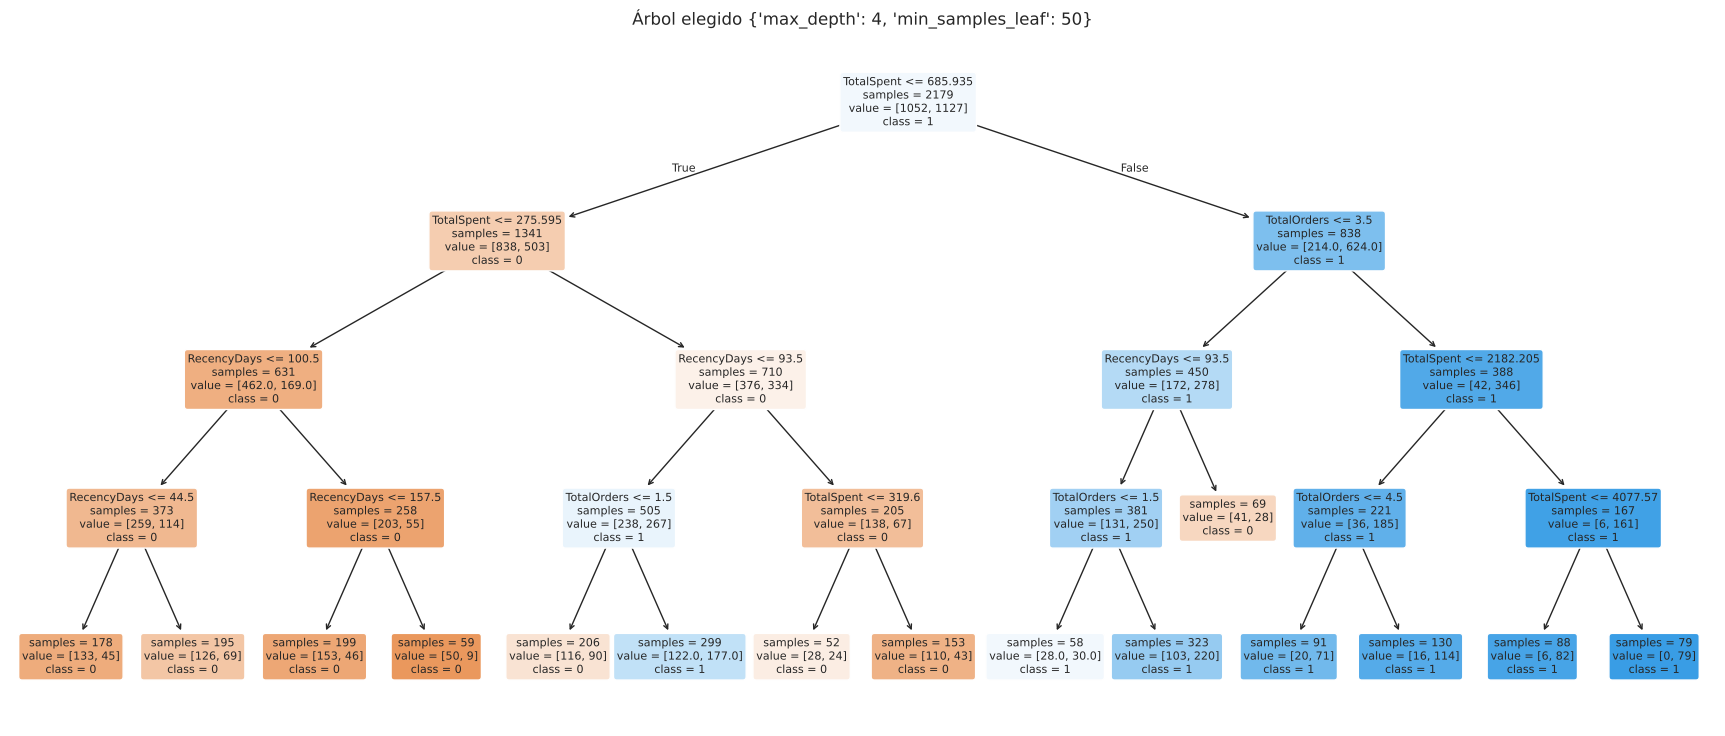

In [18]:
plt.figure(figsize=(22, 9))
plot_tree(arbol, feature_names=X.columns, class_names=["0", "1"], filled=True,
          rounded=True, impurity=False, fontsize=8)
plt.title("Árbol elegido " + str(busqueda.best_params_))
plt.savefig("figs/II_arbol.png", dpi=150)
plt.show()

In [19]:
# recorremos el árbol para escribir la regla de cada hoja
# guardamos el límite inferior y superior de cada variable en el camino
t = arbol.tree_
nombres = list(X.columns)
reglas = {}

def recorrer(nodo, limites):
    if t.children_left[nodo] == -1:   # es una hoja
        reglas[nodo] = limites
        return
    var = nombres[t.feature[nodo]]
    corte = t.threshold[nodo]
    bajo, alto = limites.get(var, (None, None))
    recorrer(t.children_left[nodo], {**limites, var: (bajo, corte)})    # var <= corte
    recorrer(t.children_right[nodo], {**limites, var: (corte, alto)})   # var > corte

recorrer(0, {})

def texto_regla(limites):
    partes = []
    for var, (bajo, alto) in limites.items():
        if bajo is not None and alto is not None:
            partes.append(f"{bajo:,.2f} < {var} <= {alto:,.2f}")
        elif bajo is not None:
            partes.append(f"{var} > {bajo:,.2f}")
        else:
            partes.append(f"{var} <= {alto:,.2f}")
    return " y ".join(partes)

hoja_train = arbol.apply(X_train)
hoja_test = arbol.apply(X_test)

filas = []
for hoja, limites in reglas.items():
    filas.append({
        "hoja": hoja,
        "regla": texto_regla(limites),
        "clientes_train": (hoja_train == hoja).sum(),
        "recompra_train": y_train[hoja_train == hoja].mean(),
        "clientes_test": (hoja_test == hoja).sum(),
        "recompra_test": y_test[hoja_test == hoja].mean(),
    })
hojas = pd.DataFrame(filas).sort_values("recompra_train", ascending=False).reset_index(drop=True)

pd.set_option("display.max_colwidth", 120)
hojas.round(3)

,hoja,regla,clientes_train,recompra_train,clientes_test,recompra_test
0,28,"TotalSpent > 4,077.57 y TotalOrders > 3.50",79,1.000,9,1.000
1,27,"2,182.20 < TotalSpent <= 4,077.57 y TotalOrders > 3.50",88,0.932,29,0.897
2,25,"685.93 < TotalSpent <= 2,182.20 y TotalOrders > 4.50",130,0.877,29,0.931
3,24,"685.93 < TotalSpent <= 2,182.20 y 3.50 < TotalOrders <= 4.50",91,0.780,23,0.826
4,20,TotalSpent > 685.93 y 1.50 < TotalOrders <= 3.50 y RecencyDays <= 93.50,323,0.681,78,0.808
5,12,275.60 < TotalSpent <= 685.93 y RecencyDays <= 93.50 y TotalOrders > 1.50,299,0.592,66,0.576
6,19,TotalSpent > 685.93 y TotalOrders <= 1.50 y RecencyDays <= 93.50,58,0.517,11,0.364
7,14,275.60 < TotalSpent <= 319.60 y RecencyDays > 93.50,52,0.462,8,0.250
8,11,275.60 < TotalSpent <= 685.93 y RecencyDays <= 93.50 y TotalOrders <= 1.50,206,0.437,71,0.380
9,21,TotalSpent > 685.93 y TotalOrders <= 3.50 y RecencyDays > 93.50,69,0.406,21,0.619


In [20]:
# elegimos las reglas solo con train: hojas con al menos 100 clientes, la de mayor y la de menor recompra
grandes = hojas[hojas["clientes_train"] >= 100]
regla_alta = grandes.iloc[0]
regla_baja = grandes.iloc[-1]

for titulo, r in [("FIDELIZACIÓN", regla_alta), ("REACTIVACIÓN", regla_baja)]:
    print(titulo)
    print("  Si", r["regla"])
    print(f"  Train: {r['clientes_train']} clientes, {r['recompra_train']:.1%} recompró")
    print(f"  Test:  {r['clientes_test']} clientes, {r['recompra_test']:.1%} recompró\n")

RES["clasificacion"]["reglas"] = {
    "alta": regla_alta.drop("hoja").to_dict(),
    "baja": regla_baja.drop("hoja").to_dict(),
}

FIDELIZACIÓN
  Si 685.93 < TotalSpent <= 2,182.20 y TotalOrders > 4.50
  Train: 130 clientes, 87.7% recompró
  Test:  29 clientes, 93.1% recompró

REACTIVACIÓN
  Si TotalSpent <= 275.60 y 100.50 < RecencyDays <= 157.50
  Train: 199 clientes, 23.1% recompró
  Test:  46 clientes, 23.9% recompró



### Las dos reglas que usamos

**Regla para fidelización.** Si el cliente gastó entre £685.93 y £2,182.20 y tiene más de 4 pedidos en el semestre, la probabilidad de que vuelva es alta. En entrenamiento son 130 clientes y el 87.7% recompró; en prueba, 29 clientes y el 93.1%. Son compradores frecuentes de gasto medio. Las hojas de al lado (más de £2,182 y más de 3 pedidos) tienen tasas todavía más altas, entre 93% y 100%, pero con menos clientes.

**Regla para reactivación.** Si el cliente gastó £275.60 o menos y lleva entre 101 y 157 días sin comprar al 1 de julio, la probabilidad de que vuelva es baja. En entrenamiento son 199 clientes y solo el 23.1% recompró; en prueba, 46 clientes y el 23.9%. Son clientes de compra pequeña que llevan de 3 a 5 meses sin regresar.

Escogimos estas dos reglas viendo solo el entrenamiento: entre las hojas con al menos 100 clientes, la de tasa más alta y la de tasa más baja. Las dos se mantienen parecidas en prueba.

También nos parece útil para reactivación la hoja de clientes que gastaron entre £319.60 y £685.93 y llevan más de 93 días sin comprar (153 clientes, 28.1% recompró). Gastaron más, así que si regresan aportan más por cliente.

Las reglas solo usan las tres variables de compra; no nos dicen por qué un cliente regresa o deja de comprar.

## II.4 Públicos, errores y piloto

In [21]:
pred_test = arbol.predict(X_test)
publicos = pd.DataFrame({
    "publico": ["Fidelización (predichos 1)", "Reactivación (predichos 0)"],
    "clientes": [(pred_test == 1).sum(), (pred_test == 0).sum()],
    "aciertos": [tp, tn],
    "error": [f"FP = {fp}", f"FN = {fn}"],
    "precision": [tp / (tp + fp), tn / (tn + fn)],
    "cobertura": [tp / (tp + fn), tn / (tn + fp)],
})
publicos.round(3)

,publico,clientes,aciertos,error,precision,cobertura
0,Fidelización (predichos 1),245,186,FP = 59,0.759,0.660
1,Reactivación (predichos 0),300,204,FN = 96,0.680,0.776


### A quién contactar y qué errores aceptamos

Proponemos empezar por la **reactivación** de los clientes que el modelo predice como 0 (300 en prueba), sobre todo los que caen en las reglas de baja recompra. Es donde una acción puede hacer más diferencia, porque sin hacer nada solo 1 de cada 4 clientes de la regla de reactivación regresó.

Los errores en prueba se ven así:

- **96 falsos negativos.** Son clientes que sí iban a regresar pero el modelo los puso en reactivación. Recibirían un incentivo que tal vez no necesitaban. Este error lo aceptamos porque el costo es un contacto o un descuento de más.
- **59 falsos positivos.** Son clientes que no regresaron pero el modelo los puso en fidelización, así que se quedarían sin que nadie los buscara. Este nos preocupa más.

Para el público de reactivación, la Precision 0 es 68.0% (de los 300 que seleccionamos, 204 de verdad no recompraron) y el Recall 0 es 77.6% (de los 263 clientes que no recompraron en prueba, encontramos a 204). Por eso elegimos F1 y no solo precisión: si subíamos la precisión de la clase 1 bajaban los falsos positivos, pero más recompradores terminaban en reactivación.

**Cómo mediríamos el piloto.** Usaríamos la tasa de recompra a 90 días: los clientes contactados que hagan al menos una compra válida en los 90 días después del contacto, entre todos los clientes que asignamos al grupo contactado (respondan o no). La comparamos contra un grupo de control elegido al azar dentro del mismo público (por ejemplo, entre 20% y 30%) al que no le mandamos nada, en el mismo plazo. La diferencia entre las dos tasas es lo que podríamos atribuir a la campaña. El árbol solo nos dice quién tiende a regresar, no que una promoción haga que compren.

Dos cosas a tener en cuenta. Que un cliente sea clase 0 no significa que se perdió para siempre: en la actividad 3 vimos que 462 de los 1,315 clientes sin recompra en esos 90 días (35%) volvieron a comprar después. Y este análisis es de julio a septiembre de 2011, así que no lo mezclamos con los segmentos de diciembre de la sección III.

---
# III. Clustering y marketing por segmentación
Todos los clientes identificados hasta el 9-dic-2011 (referencia 10-dic-2011). Es otra población y otro periodo que la sección II, así que estos segmentos **no** se aplican a la campaña de julio. No usamos `CustomerID` ni `Repurchase90Days`.

In [22]:
rfm = pd.read_csv(DATA + "clientes_rfm.csv")
vars_rfm = ["Recency", "Frequency", "Monetary"]

print("Asimetría:")
print(rfm[vars_rfm].skew().round(1))

negativos = rfm[rfm["Monetary"] <= 0]
print("\nMonetary <= 0:", len(negativos), "clientes", f"({len(negativos) / len(rfm):.2%})",
      "| importe:", gbp(negativos["Monetary"].sum()))
rfm[vars_rfm].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(1)

Asimetría:
Recency       0.9
Frequency    12.6
Monetary     26.7
dtype: float64

Monetary <= 0: 35 clientes (0.60%) | importe: £-31,587


,Recency,Frequency,Monetary
count,5878.0,5878.0,5878.0
mean,201.9,6.3,2781.7
std,209.4,13.0,13741.2
min,1.0,1.0,-10953.5
25%,26.0,1.0,329.7
50%,96.0,3.0,838.9
75%,380.0,7.0,2165.3
95%,626.0,21.0,8860.8
99%,727.0,46.0,26358.9
max,739.0,398.0,570380.6


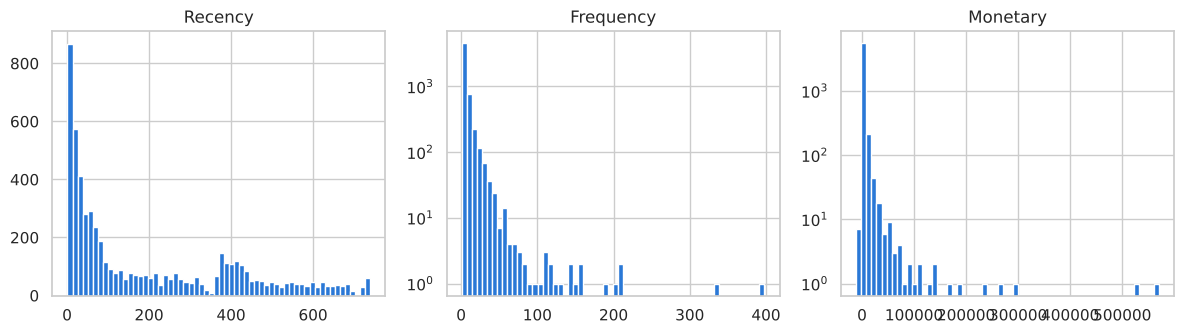

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
for i, var in enumerate(vars_rfm):
    ax[i].hist(rfm[var], bins=60, color=azul)
    ax[i].set_title(var)
ax[1].set_yscale("log")
ax[2].set_yscale("log")
plt.tight_layout()
plt.show()

## III.1 Transformaciones
- **Recency** y **Frequency** siempre son 1 o más, así que usamos `log1p`.
- **Monetary** tiene 35 clientes con importe neto de cero o negativo (ruta B). No podemos usar `log1p` directo ni volverlos positivos, así que usamos el **logaritmo con signo**: `sign(x) * log(1 + |x|)`. Conserva el signo y reduce la cola de valores muy grandes.
- Luego estandarizamos con `StandardScaler`. Para describir los perfiles usamos los valores originales.
- **No excluimos a nadie.** También probamos Yeo-Johnson (celda siguiente), pero los grupos más pequeños quedaban formados por casos extremos: los 12 clientes con mayor importe (más de £109,000) y, con k=6, un solo cliente con −£10,954. Esos grupos no sirven para una campaña.

In [24]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

transformado = pd.DataFrame({
    "Recency": np.log1p(rfm["Recency"]),
    "Frequency": np.log1p(rfm["Frequency"]),
    "Monetary": np.sign(rfm["Monetary"]) * np.log1p(rfm["Monetary"].abs()),
})
Z = StandardScaler().fit_transform(transformado)

# mismos parámetros para todos los k: init k-means++, n_init=10, random_state=42
kmeans = {}
filas = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit(Z)
    kmeans[k] = km
    tamanos = np.bincount(km.labels_)
    filas.append({"k": k, "inercia": km.inertia_, "silhouette": silhouette_score(Z, km.labels_),
                  "grupo_menor": tamanos.min(), "tamanos": sorted(tamanos)})
eleccion_k = pd.DataFrame(filas)
print("Silhouette calculada con los", len(Z), "clientes (sin muestra)")
eleccion_k.round(3)

Silhouette calculada con los 5878 clientes (sin muestra)


,k,inercia,silhouette,grupo_menor,tamanos
0,2,9159.184,0.432,2369,"[2369, 3509]"
1,3,7037.042,0.343,1224,"[1224, 2301, 2353]"
2,4,5646.749,0.357,1221,"[1221, 1303, 1491, 1863]"
3,5,4550.332,0.374,43,"[43, 1122, 1286, 1391, 2036]"
4,6,3805.488,0.356,42,"[42, 449, 1139, 1236, 1288, 1724]"
5,7,3311.591,0.341,42,"[42, 438, 711, 905, 1071, 1186, 1525]"
6,8,2999.099,0.319,42,"[42, 260, 709, 739, 831, 853, 1099, 1345]"


In [25]:
# comparación: Yeo-Johnson en lugar del logaritmo con signo (mismos parámetros de K-Means)
from sklearn.preprocessing import PowerTransformer

Z_yj = StandardScaler().fit_transform(PowerTransformer(method="yeo-johnson").fit_transform(rfm[vars_rfm]))
for k in [4, 5, 6]:
    etiquetas_yj = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit_predict(Z_yj)
    tamanos = np.bincount(etiquetas_yj)
    chico = tamanos.argmin()
    print(f"k={k} | tamaños: {sorted(tamanos.tolist())} | Monetary del grupo más chico: "
          f"{gbp(rfm['Monetary'][etiquetas_yj == chico].min())} a {gbp(rfm['Monetary'][etiquetas_yj == chico].max())}")

k=4 | tamaños: [12, 1462, 1963, 2441] | Monetary del grupo más chico: £109,893 a £570,381
k=5 | tamaños: [12, 1258, 1264, 1559, 1785] | Monetary del grupo más chico: £109,893 a £570,381
k=6 | tamaños: [1, 12, 1260, 1265, 1549, 1791] | Monetary del grupo más chico: £-10,954 a £-10,954


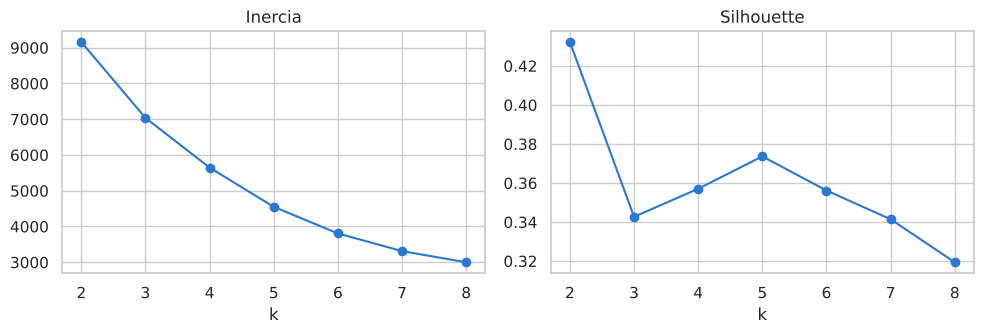

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(eleccion_k["k"], eleccion_k["inercia"], marker="o", color=azul)
ax[0].set_title("Inercia")
ax[1].plot(eleccion_k["k"], eleccion_k["silhouette"], marker="o", color=azul)
ax[1].set_title("Silhouette")
for a in ax:
    a.set_xlabel("k")
plt.tight_layout()
plt.savefig("figs/III_inercia_silhouette.png", dpi=150)
plt.show()

### Cuántos grupos elegimos

La inercia baja poco a poco sin un codo claro, así que por sí sola no nos ayuda a decidir. La silhouette más alta es la de k=2 (0.432), pero con dos grupos solo separamos activos de inactivos y no da para acciones diferentes. Entre las opciones con más grupos, **k=5 tiene la mejor silhouette (0.374)**, arriba de k=4 (0.357) y de k=6 a 8. Desde k=5 aparece un grupo chico (43 clientes en k=5 y 42 de k=6 a k=8) que se mantiene en todas esas soluciones: son los clientes con saldo neto de cero o negativo por los abonos de la ruta B.

In [27]:
def perfil(k):
    etiquetas = kmeans[k].labels_
    # renumeramos los grupos de menor a mayor Monetary para que los nombres no cambien
    orden = rfm.groupby(etiquetas)["Monetary"].median().sort_values().index
    nuevo = {viejo: i for i, viejo in enumerate(orden)}
    etiquetas = np.array([nuevo[e] for e in etiquetas])

    p = rfm.groupby(etiquetas).agg(
        clientes=("CustomerID", "count"),
        recency_med=("Recency", "median"),
        frequency_med=("Frequency", "median"),
        monetary_med=("Monetary", "median"),
        monetary_total=("Monetary", "sum"),
    )
    p["pct_clientes"] = p["clientes"] / len(rfm) * 100
    p["pct_importe"] = p["monetary_total"] / rfm["Monetary"].sum() * 100
    return etiquetas, p

etiq4, perfil4 = perfil(4)
etiq5, perfil5 = perfil(5)
print("k = 4")
display(perfil4.round(1))
print("k = 5")
display(perfil5.round(1))
print("Cruce k=4 (filas) contra k=5 (columnas)")
pd.crosstab(etiq4, etiq5)

k = 4


,clientes,recency_med,frequency_med,monetary_med,monetary_total,pct_clientes,pct_importe
0,1863,411.0,1.0,247.9,516166.2,31.7,3.2
1,1303,25.0,3.0,702.8,1093469.3,22.2,6.7
2,1491,193.0,4.0,1320.6,2592365.4,25.4,15.9
3,1221,17.0,13.0,4733.5,12149040.0,20.8,74.3


k = 5


,clientes,recency_med,frequency_med,monetary_med,monetary_total,pct_clientes,pct_importe
0,43,429.0,1.0,-0.0,-31582.2,0.7,-0.2
1,2036,405.0,1.0,291.9,727112.2,34.6,4.4
2,1286,25.0,3.0,699.0,1060028.0,21.9,6.5
3,1391,158.0,5.0,1558.2,2835587.5,23.7,17.3
4,1122,16.0,13.0,4961.2,11759895.5,19.1,71.9


Cruce k=4 (filas) contra k=5 (columnas)


col_0,0,1,2,3,4
row_0,,,,,
0,42,1817,4,0,0
1,1,12,1267,23,0
2,0,207,9,1275,0
3,0,0,6,93,1122


### Por qué k=5 y no k=4

En el cruce entre las dos soluciones vemos dos ventajas de k=5:

1. Separa a los 43 clientes con saldo neto de cero, negativo o casi cero (35 con Monetary ≤ 0; de los otros 8, seis tienen compras y abonos que se cancelan y quedan en cero salvo por redondeo, y dos tienen menos de £3). Con k=4 quedan mezclados con los compradores inactivos y les mandaríamos una campaña de reactivación, cuando lo que necesitan es que se revisen sus abonos.
2. Los grupos activos quedan más definidos. 93 clientes que en k=4 estaban en el grupo de mayor valor pasan a "recurrentes en enfriamiento", y 207 clientes de enfriamiento pasan a "únicos inactivos". El grupo de mayor valor queda más compacto: compraron hace 16 días (mediana) y llevan 13 pedidos.

Los cuatro segmentos principales tienen entre 19% y 35% de los clientes, un tamaño razonable para hacer una campaña con cada uno.

In [28]:
nombres_seg = {0: "Saldo neto nulo o negativo",
               1: "Compradores únicos inactivos",
               2: "Recientes en desarrollo",
               3: "Recurrentes en enfriamiento",
               4: "Clientes clave activos"}
rfm["Segmento"] = [nombres_seg[e] for e in etiq5]
perfil_final = perfil5.rename(index=nombres_seg)
perfil_final.round(1)

,clientes,recency_med,frequency_med,monetary_med,monetary_total,pct_clientes,pct_importe
Saldo neto nulo o negativo,43,429.0,1.0,-0.0,-31582.2,0.7,-0.2
Compradores únicos inactivos,2036,405.0,1.0,291.9,727112.2,34.6,4.4
Recientes en desarrollo,1286,25.0,3.0,699.0,1060028.0,21.9,6.5
Recurrentes en enfriamiento,1391,158.0,5.0,1558.2,2835587.5,23.7,17.3
Clientes clave activos,1122,16.0,13.0,4961.2,11759895.5,19.1,71.9


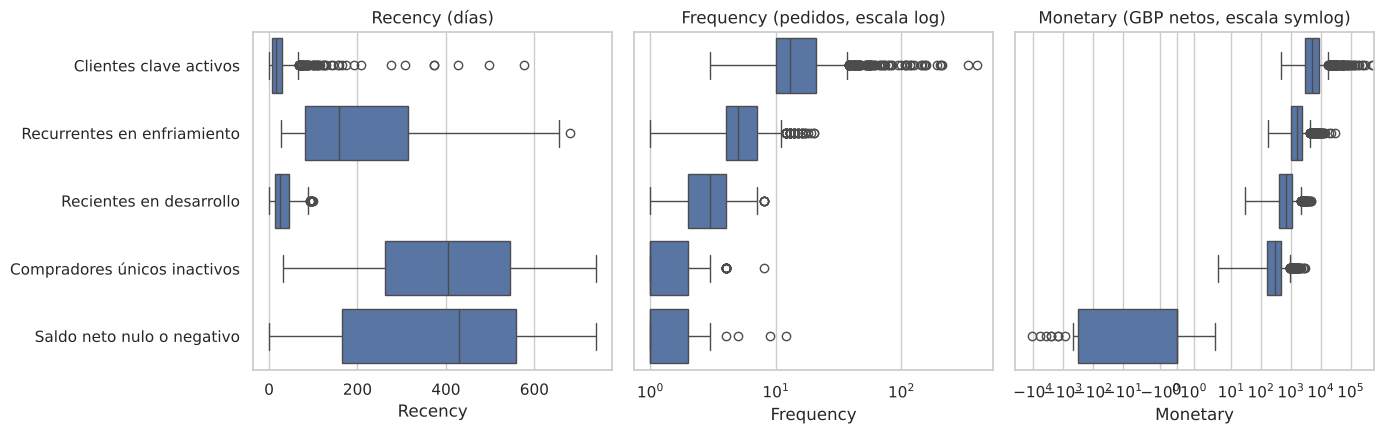

In [29]:
orden = ["Clientes clave activos", "Recurrentes en enfriamiento", "Recientes en desarrollo",
         "Compradores únicos inactivos", "Saldo neto nulo o negativo"]

fig, ax = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
sns.boxplot(data=rfm, x="Recency", y="Segmento", order=orden, ax=ax[0])
sns.boxplot(data=rfm, x="Frequency", y="Segmento", order=orden, ax=ax[1])
sns.boxplot(data=rfm, x="Monetary", y="Segmento", order=orden, ax=ax[2])
ax[0].set_title("Recency (días)")
ax[1].set_title("Frequency (pedidos, escala log)")
ax[1].set_xscale("log")
ax[2].set_title("Monetary (GBP netos, escala symlog)")
ax[2].set_xscale("symlog")
ax[0].set_ylabel("")
plt.tight_layout()
plt.savefig("figs/III_boxplots_segmentos.png", dpi=150)
plt.show()

RES["clustering"] = {
    "k": 5,
    "k_candidato": 4,
    "silhouette": {int(k): round(s, 4) for k, s in zip(eleccion_k["k"], eleccion_k["silhouette"])},
    "segmentos": perfil_final.round(4).to_dict("index"),
    "monetary_le0": {"n": len(negativos), "importe": round(negativos["Monetary"].sum(), 2)},
}

### Los segmentos y qué probaríamos en cada uno

Estos segmentos describen a los clientes al 10 de diciembre de 2011.

**Clientes clave activos** (1,122 clientes, 19.1%). Medianas: compraron hace 16 días, llevan 13 pedidos y gastaron £4,961. Juntos son el 71.9% del importe neto. Probaríamos un programa de cliente preferente: acceso anticipado al catálogo de temporada y atención directa. Queremos que mantengan su frecuencia de compra. Lo mediríamos con el porcentaje que hace un pedido en los siguientes 60 días, comparado con un grupo de control del mismo segmento.

**Recurrentes en enfriamiento** (1,391 clientes, 23.7%). Medianas: compraron hace 158 días, llevan 5 pedidos y gastaron £1,558. Son el 17.3% del importe. Probaríamos un recordatorio con productos que ya compraron y un incentivo para volver a pedir con fecha límite. Queremos que pase menos tiempo antes de su siguiente pedido. Lo mediríamos con la tasa de recompra a 90 días contra un grupo de control.

**Recientes en desarrollo** (1,286 clientes, 21.9%). Medianas: compraron hace 25 días, llevan 3 pedidos y gastaron £699. El 59% compró en el último mes. Son el 6.5% del importe. Probaríamos una serie de correos para motivar el segundo y tercer pedido (novedades, envío con pedido mínimo). Queremos que pasen de comprar de vez en cuando a comprar seguido. Lo mediríamos con el porcentaje que hace 2 pedidos más en 90 días contra un grupo de control.

**Compradores únicos inactivos** (2,036 clientes, 34.6%). Medianas: compraron hace 405 días, llevan 1 pedido y gastaron £292. El 65% compró una sola vez y el 63% no compra desde hace más de un año. Son el 4.4% del importe. Probaríamos una campaña de bajo costo por correo con una sola oferta para regresar. Queremos lograr su segunda compra. Lo mediríamos con cuántos compran en 60 días entre los contactados, contra un grupo de control.

**Saldo neto nulo o negativo** (43 clientes, 0.7%). Su importe neto es cercano a cero o negativo por los abonos. A este grupo no le haríamos campaña; propondríamos revisar con atención a clientes sus devoluciones y abonos, y documentar la causa de cada caso.

Los dos segmentos con estrategias más distintas son los **clientes clave activos** y los **compradores únicos inactivos**. Los primeros son el 19.1% de los clientes y concentran el 71.9% del importe neto, y compran seguido. Los segundos son la tercera parte de la base (34.6%), la mayoría compró una sola vez y hace más de un año, y aportan el 4.4%. A los primeros hay que cuidarlos; con los segundos solo probaríamos una acción barata.

Las medianas describen cómo compran los clientes (cuándo, cuántas veces y cuánto), no cuánto ganamos con ellos ni por qué compran. RFM no incluye márgenes ni costos.

---
# Cifras clave
Guardamos las cifras en `resultados_a4.json` para usar los mismos números en las slides y el reporte.

In [30]:
with open("resultados_a4.json", "w", encoding="utf-8") as archivo:
    json.dump(RES, archivo, ensure_ascii=False, indent=1, default=lambda x: x.item())
print("Guardado resultados_a4.json")

Guardado resultados_a4.json


## Resumen para la presentación

**Pronóstico.** Nuestro modelo Ridge con rezagos y calendario pronostica mejor que la referencia: MAE de £10,481 contra £13,236 (21% menos) y error semanal de 9.0% contra 13.0%. Lo usaríamos para planear la capacidad semanal de octubre a diciembre, con un margen extra para los picos porque tiende a quedarse corto. Para darle seguimiento compararíamos su MAE semanal contra la referencia en cada nuevo periodo.

**Recompra (julio de 2011).** Encontramos 199 clientes de compra pequeña y de 3 a 5 meses sin comprar con solo 23% de recompra. El árbol tiene F1 de 0.706 en prueba y encuentra al 77.6% de los clientes que no regresan. **Nuestra acción prioritaria es un piloto de reactivación con grupo de control**, medido con la tasa de recompra a 90 días.

**Segmentos (diciembre de 2011).** El 19% de los clientes concentra el 72% del importe neto, y el 35% está en el grupo de inactivos, que en su mayoría compró una sola vez y hace más de un año. Proponemos un programa preferente para los clientes clave y recordatorios con fecha límite para los recurrentes en enfriamiento, midiendo la recompra a 60–90 días contra un grupo de control en cada segmento.

**Limitaciones que podrían cambiar nuestras decisiones:**
- Solo tenemos un año previo de noviembre y diciembre para el pronóstico.
- Que un cliente no recompre en 90 días no significa que se perdió.
- Las campañas son pruebas; no calculamos rentabilidad porque no tenemos costos ni efectos medidos.
- La clasificación (julio) y la segmentación (diciembre) son fotos distintas de los clientes.